Latihan: Data Loading

In [6]:
import pandas as pd

# Memuat dataset train dan test
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Menampilkan 5 baris pertama dari data train untuk memastikan data berhasil dimuat
train.head()

,Luas_Tanah,Jumlah_Kamar,Jarak_Pusat_Kota,Usia_Bangunan,Harga_Rumah
0,483,3,16.52,9,7171.63
1,313,1,15.26,6,4558.87
2,436,3,19.67,13,6425.17
3,213,3,2.30,17,3274.24
4,470,5,9.31,1,7213.64


In [7]:
import pandas as pd

# Memuat dataset train dan test
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Menampilkan 5 baris pertama dari data train untuk memastikan data berhasil dimuat
test.head()

,Luas_Tanah,Jumlah_Kamar,Jarak_Pusat_Kota,Usia_Bangunan,Harga_Rumah
0,489,4,11.88,10,7339.70
1,131,3,8.76,29,1876.02
2,330,5,5.54,29,4974.22
3,282,4,3.91,0,4409.62
4,314,1,2.32,28,4616.60


Latihan: Data Cleaning dan Transformation

In [8]:
import pandas as pd
train = pd.read_csv('train.csv')

Mengidentifikasi Informasi Dataset

In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Luas_Tanah        4000 non-null   int64  
 1   Jumlah_Kamar      4000 non-null   int64  
 2   Jarak_Pusat_Kota  4000 non-null   float64
 3   Usia_Bangunan     4000 non-null   int64  
 4   Harga_Rumah       4000 non-null   float64
dtypes: float64(2), int64(3)
memory usage: 156.4 KB


In [10]:
train.describe(include="all")

,Luas_Tanah,Jumlah_Kamar,Jarak_Pusat_Kota,Usia_Bangunan,Harga_Rumah
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,276.342250,2.989250,12.777395,14.397250,4094.932652
std,130.371975,1.416734,6.854798,8.572883,1957.101239
min,50.000000,1.000000,1.000000,0.000000,527.850000
25%,165.750000,2.000000,6.920000,7.000000,2433.002500
50%,276.000000,3.000000,12.650000,14.000000,4109.140000
75%,391.000000,4.000000,18.612500,22.000000,5810.532500
max,499.000000,5.000000,24.990000,29.000000,7661.610000


In [11]:
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

Mengatasi Missing Value

In [12]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [13]:
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [14]:
katagorical_features = train[less].select_dtypes(include=['object']).columns
for col in katagorical_features:
    train[col] = train[col].fillna(train[col].mode()[0])

In [15]:
df = train.drop(columns=over)

In [16]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

Mengatasi Outliers

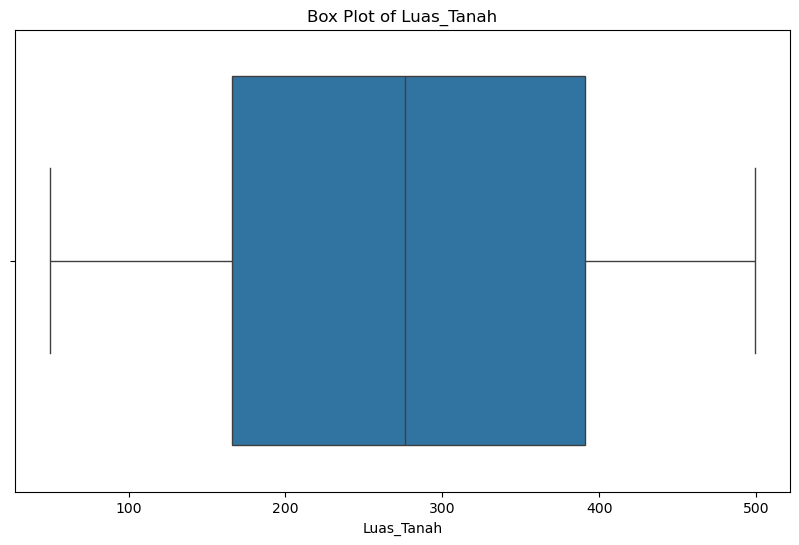

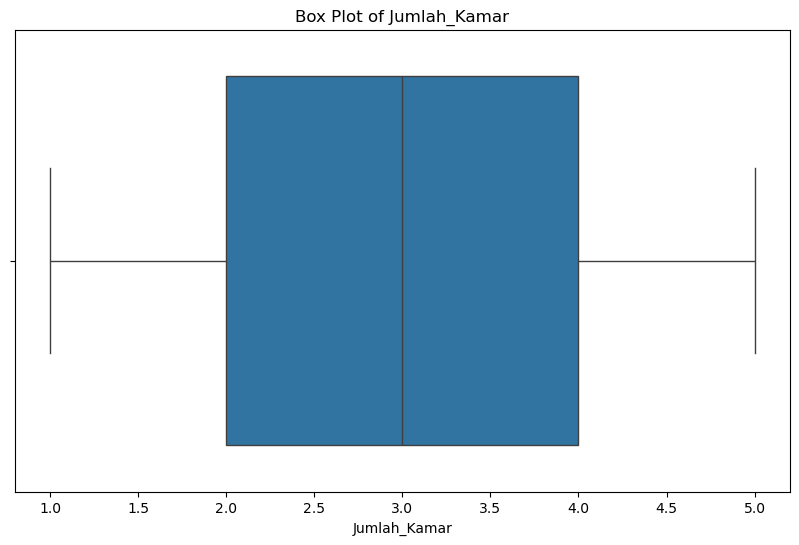

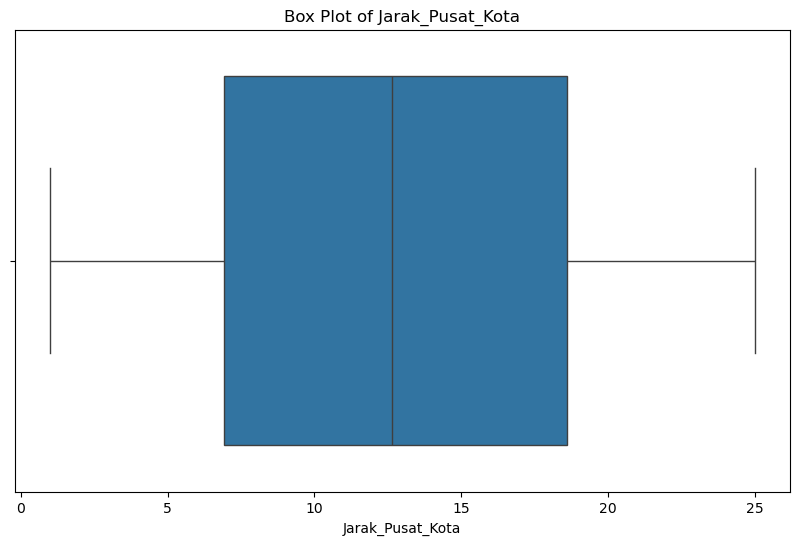

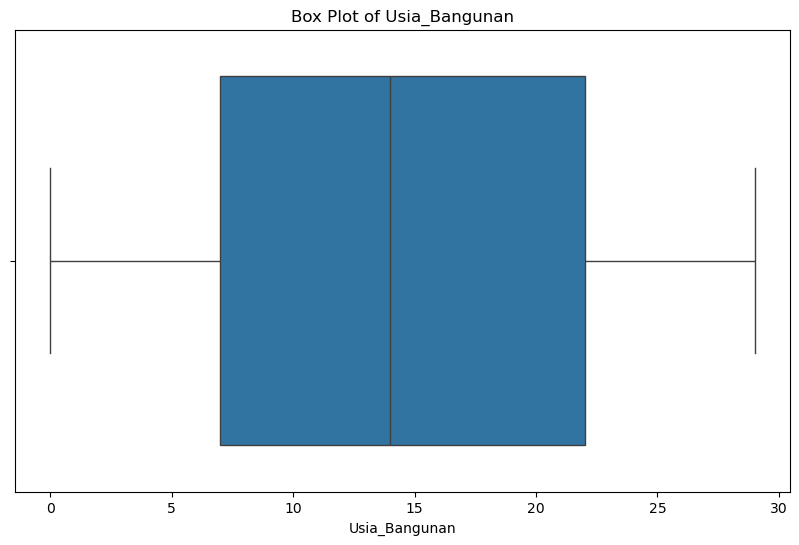

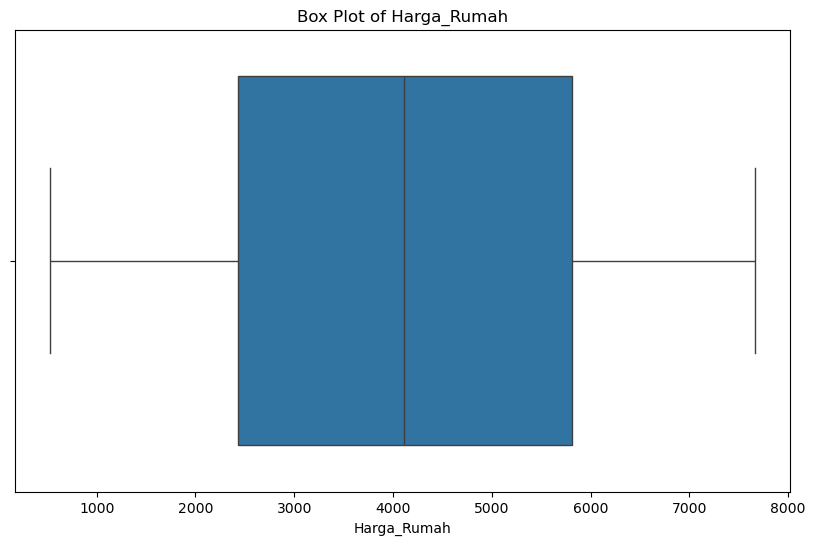

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [18]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [19]:
# Pastikan ulang kolom numerik terambil dari dataframe df yang aktif
numeric_features = df.select_dtypes(include=['number']).columns

# Hitung kembali Q1, Q3, dan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

# Filter dataframe untuk menyaring outliers
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR)))
df_filtered_numeric = df.loc[condition.all(axis=1), numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition.all(axis=1), categorical_features]], axis=1)

Normalisasi dan Standardisasi Data

In [20]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

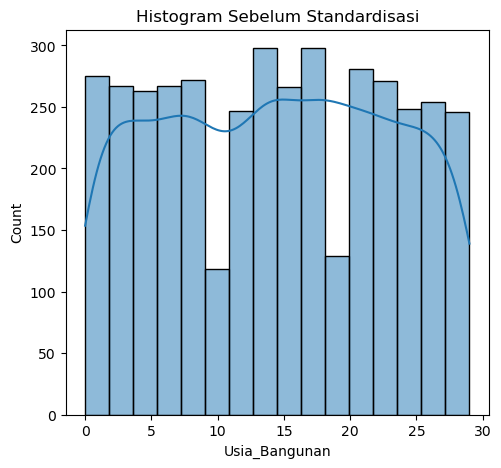

In [21]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

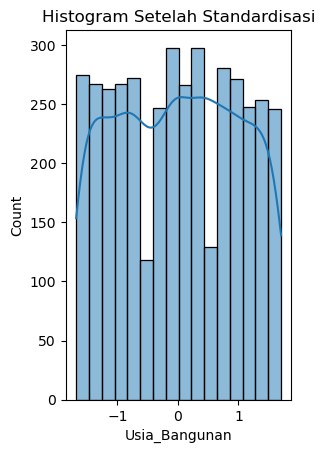

In [22]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")
plt.show()

Menangani Duplikasi Data

In [23]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()
print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Luas_Tanah, Jumlah_Kamar, Jarak_Pusat_Kota, Usia_Bangunan, Harga_Rumah]
Index: []


In [24]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print("DataFrame setelah menghapus duplikasi:")
print(df)

DataFrame setelah menghapus duplikasi:
      Luas_Tanah  Jumlah_Kamar  Jarak_Pusat_Kota  Usia_Bangunan  Harga_Rumah
0       1.585338      0.007589          0.546052      -0.629651     1.572265
1       0.281213     -1.404285          0.362216      -0.979635     0.237083
2       1.224786      0.007589          1.005641      -0.163005     1.190806
3      -0.485919      0.007589         -1.528667       0.303641    -0.419393
4       1.485610      1.419463         -0.505898      -1.562943     1.593733
...          ...           ...               ...            ...          ...
3995   -1.475519      0.713526         -0.176161       1.586917    -1.457196
3996    1.393555      1.419463         -1.055947      -0.979635     1.508704
3997    1.301499     -1.404285         -1.136192       0.420302     1.280624
3998   -1.483190     -0.698348         -0.443160      -1.096297    -1.462796
3999   -0.378520     -0.698348         -1.699372      -0.862974    -0.315134

[4000 rows x 5 columns]


Mengonversi Tipe Data

In [25]:
# Menampilkan kolom kategorikal pada dataset
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

""
0
1
2
3
4
...
3995
3996
3997
3998


In [26]:
# Mengubah kolom kategorikal menjadi format biner (one-hot encoding)
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Luas_Tanah,Jumlah_Kamar,Jarak_Pusat_Kota,Usia_Bangunan,Harga_Rumah
0,1.585338,0.007589,0.546052,-0.629651,1.572265
1,0.281213,-1.404285,0.362216,-0.979635,0.237083
2,1.224786,0.007589,1.005641,-0.163005,1.190806
3,-0.485919,0.007589,-1.528667,0.303641,-0.419393
4,1.485610,1.419463,-0.505898,-1.562943,1.593733
...,...,...,...,...,...
3995,-1.475519,0.713526,-0.176161,1.586917,-1.457196
3996,1.393555,1.419463,-1.055947,-0.979635,1.508704
3997,1.301499,-1.404285,-1.136192,0.420302,1.280624
3998,-1.483190,-0.698348,-0.443160,-1.096297,-1.462796


In [27]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil label encoding
df_lencoder

,Luas_Tanah,Jumlah_Kamar,Jarak_Pusat_Kota,Usia_Bangunan,Harga_Rumah
0,1.585338,0.007589,0.546052,-0.629651,1.572265
1,0.281213,-1.404285,0.362216,-0.979635,0.237083
2,1.224786,0.007589,1.005641,-0.163005,1.190806
3,-0.485919,0.007589,-1.528667,0.303641,-0.419393
4,1.485610,1.419463,-0.505898,-1.562943,1.593733
...,...,...,...,...,...
3995,-1.475519,0.713526,-0.176161,1.586917,-1.457196
3996,1.393555,1.419463,-1.055947,-0.979635,1.508704
3997,1.301499,-1.404285,-1.136192,0.420302,1.280624
3998,-1.483190,-0.698348,-0.443160,-1.096297,-1.462796


Latihan EDA & ExDA

In [28]:
df_lencoder.head()

,Luas_Tanah,Jumlah_Kamar,Jarak_Pusat_Kota,Usia_Bangunan,Harga_Rumah
0,1.585338,0.007589,0.546052,-0.629651,1.572265
1,0.281213,-1.404285,0.362216,-0.979635,0.237083
2,1.224786,0.007589,1.005641,-0.163005,1.190806
3,-0.485919,0.007589,-1.528667,0.303641,-0.419393
4,1.485610,1.419463,-0.505898,-1.562943,1.593733


In [29]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]  # Menampilkan kolom dengan missing values

,Missing Values,Percentage


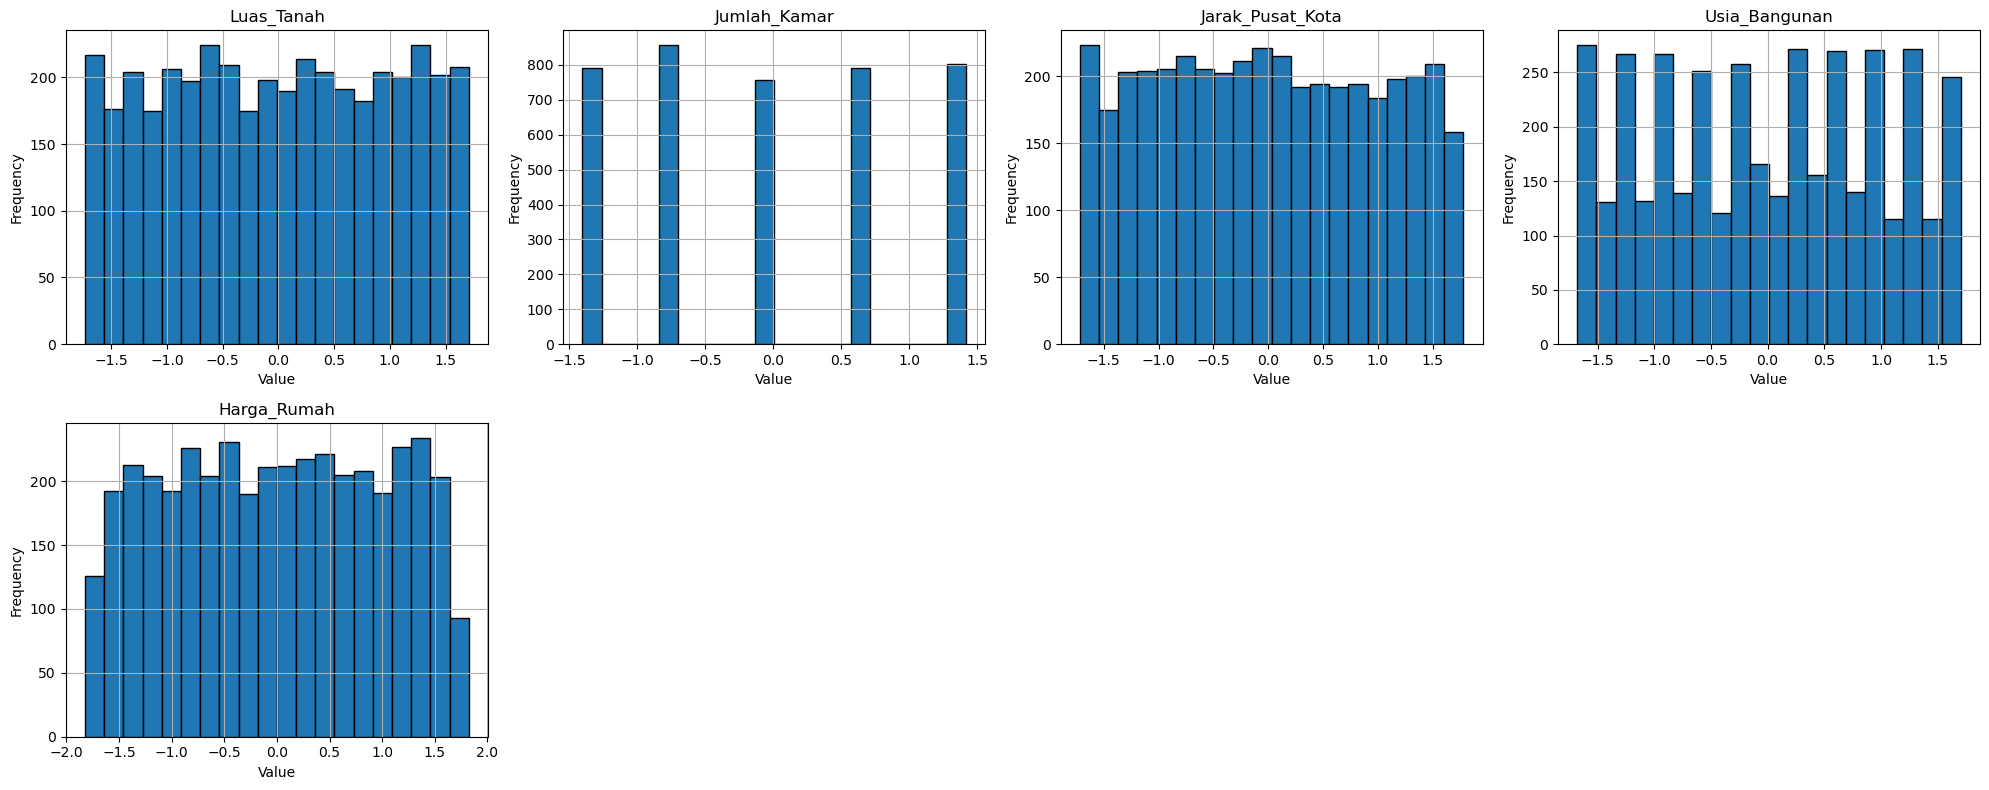

In [30]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4  # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols)  # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

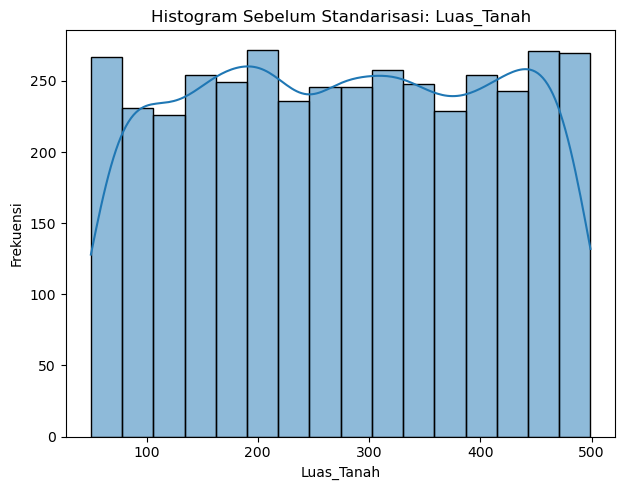

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan nama dataframe-nya sesuai (misal train)
# Mengambil kolom numerik secara otomatis
numeric_features = train.select_dtypes(include=['number']).columns

# Menampilkan histogram untuk kolom pertama (indeks 0) yang aman
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)

# Cek apakah kolomnya ada minimal 1
if len(numeric_features) > 0:
    sns.histplot(train[numeric_features[0]], kde=True)
    plt.title(f"Histogram Sebelum Standarisasi: {numeric_features[0]}")
    plt.xlabel(numeric_features[0])
    plt.ylabel("Frekuensi")
else:
    print("Tidak ada kolom numerik yang ditemukan.")

plt.tight_layout()
plt.show()

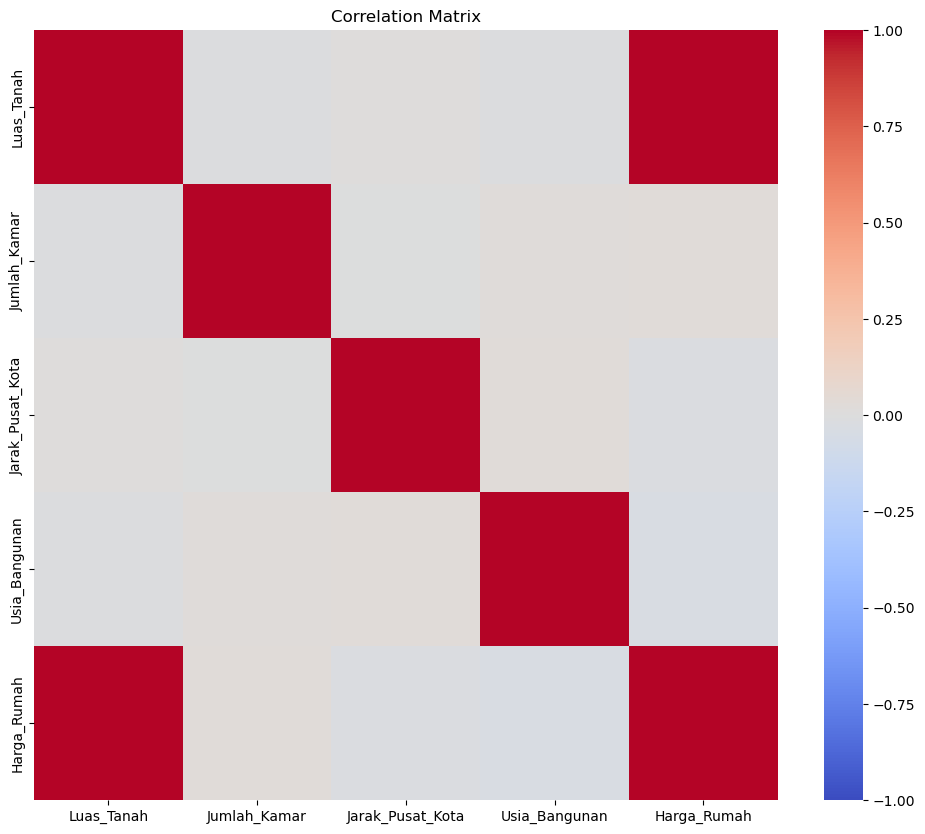

In [32]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

In [33]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

california = fetch_california_housing(as_frame=True)
df_lencoder = california.frame

Latihan: Data Splitting

In [34]:
import sklearn

In [35]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['MedHouseVal'])  
y = df_lencoder['MedHouseVal']

In [36]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [37]:
# menghitung panjang/jumlah data 
print("Jumlah data: ", len(X))

# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ", len(x_train))

# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ", len(x_test))

Jumlah data:  20640
Jumlah data latih:  16512
Jumlah data test:  4128


Pembangunan Model (Modelling)

Melatih Model (Training)

In [38]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


Evaluasi Model

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

,MAE,MSE,R2
Lars,0.908828,1.312639,-0.000723


In [40]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.908828,1.312639,-0.000723
Linear Regression,0.532869,0.529140,0.596597


In [41]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.908828,1.312639,-0.000723
Linear Regression,0.532869,0.529140,0.596597
GradientBoostingRegressor,0.369797,0.289845,0.779029


Menyimpan Model

Joblib

In [42]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

print("Model GBR berhasil disimpan ke file gbr_model.joblib!")

Model GBR berhasil disimpan ke file gbr_model.joblib!


Pickle

In [43]:
import pickle

# Menyimpan model ke dalam file
with open('gbr_model.pkl', 'wb') as file:
    pickle.dump(GBR, file)

print("Model GBR berhasil disimpan ke file gbr_model.pkl!")

Model GBR berhasil disimpan ke file gbr_model.pkl!


In [44]:
import pandas as pd

# Membaca file dataset (ganti nama filenya jika berbeda, misal train.csv atau test.csv)
df = pd.read_csv('train.csv')

# Menampilkan jumlah baris dan kolom
print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom: {df.shape[1]}")

# Kalau mau lihat ringkasan lengkapnya
print(df.info())

Jumlah baris: 4000
Jumlah kolom: 5
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Luas_Tanah        4000 non-null   int64  
 1   Jumlah_Kamar      4000 non-null   int64  
 2   Jarak_Pusat_Kota  4000 non-null   float64
 3   Usia_Bangunan     4000 non-null   int64  
 4   Harga_Rumah       4000 non-null   float64
dtypes: float64(2), int64(3)
memory usage: 156.4 KB
None


Deployment dan Monitoring

In [45]:
# Membuat model dari file joblib
joblib_model = joblib.load('gbr_model.joblib')

#Memuat model dari file pickel
with open ('gbr_model.pkl', 'rb') as file:
    pickle_model = pickle.load(file)

In [48]:
import requests

# Kirim data dengan tepat 8 fitur saja sesuai ekspektasi model
payload = {
    "data": [
        [1.5, 2.0, 3.1, 4.2, 5.0, 6.1, 7.2, 8.0]
    ]
}

response = requests.post("http://127.0.0.1:8080/predict", json=payload)
print("Status:", response.status_code)
print("Hasil Prediksi:", response.json())

Status: 200
Hasil Prediksi: {'prediction': [0.579139129298034]}
